# Aluminium arbitrage — 02 Research & results

**Question.** Where should the next tonne of primary aluminium go? For five origins and three destinations, what does a tonne net back at its loading port over LME cash, which destination pays the most, and what would have to move for the answer to change?

This notebook reads the point-in-time dataset built in `01_data.ipynb` and performs no data operation of its own. Notebook 03 checks the answer against the tonnes that actually moved.

In [1]:
import sys
sys.path.insert(0, "..")

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config as c, data, netback, sql, voyage

pd.set_option("display.float_format", "{:,.1f}".format)
pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", None)
plt.rcParams.update({"figure.figsize": (10, 3.2), "axes.grid": True, "grid.alpha": .3})
COLORS = {"midwest": "C0", "rotterdam": "C1", "japan": "C2"}
ORIGINS = list(c.ORIGINS)

In [2]:
# every origin at every destination on every trade date, by the route the rule picks
nb = netback.table()
wide = nb.pivot_table(index="trade_date", columns=["origin", "destination"], values="netback")
best = pd.DataFrame({origin: wide[origin].idxmax(axis=1) for origin in ORIGINS})
last = wide.index[-1]

## 1. Key findings

In [3]:
today = wide.loc[last].unstack().loc[ORIGINS, list(c.DESTINATIONS)]
ladder = netback.tipping(nb, last)
findings = today.copy()
findings["best"] = today.idxmax(axis=1)
findings["lead over second"] = today.apply(lambda row: row.nlargest(2).diff().iloc[-1] * -1, axis=1)
findings["days best: midwest / rotterdam / japan, %"] = [" / ".join(f"{100 * (best[o] == d).mean():.0f}" for d in c.DESTINATIONS) for o in ORIGINS]
print(f"{len(wide):,} trade dates, {wide.index[0]:%d %b %Y} to {last:%d %b %Y}; netback in USD/t FOB over LME cash on {last:%d %b %Y}")
findings

2,688 trade dates, 01 Apr 2016 to 17 Nov 2026; netback in USD/t FOB over LME cash on 17 Nov 2026


destination,midwest,rotterdam,japan,best,lead over second,"days best: midwest / rotterdam / japan, %"
origin,,,,,,
quebec,500.9,383.8,2.3,midwest,117.2,91 / 9 / 0
iceland,416.6,483.5,-23.9,rotterdam,67.0,34 / 66 / 0
gulf,114.5,122.5,25.2,rotterdam,8.0,58 / 23 / 20
india,149.6,175.2,128.3,rotterdam,25.6,36 / 12 / 52
malaysia,152.7,163.6,176.2,japan,12.6,21 / 7 / 72


Data through 17 November 2026, 2,688 trade dates since April 2016. Netbacks are premiums FOB at the origin port over LME cash.

1. **Today the metal goes three ways.** Quebec nets back 501 USD/t in the Midwest, 117 more than in Rotterdam. Iceland, the Gulf and India do best in Rotterdam, Malaysia in Japan.
2. **The Midwest is the destination at the margin.** At the premium quoted for their arrival month, the Gulf, India and Malaysia are 0.5 to 1.7 US cents per pound from switching to the Midwest (section 5). Quebec would leave it for Europe only below 100 c/lb, 8 cents under today's quote.
3. **Four fifths of the Midwest premium pays the tariff.** Of 2,276 USD/t on 17 November, 1,779 pays the 50% section 232 duty and about 500 is premium. That premium averaged 206 in 2025 and 484 so far in 2026, against 300 to 350 in 2021-22 (section 6).
4. **The duty decides, and Quebec's turn to Europe is in the replay.** Under the 25% duty, from 12 March to 3 June 2025, Rotterdam paid Quebec more on 75% of days, against 13% under the 10% duty. Under 50% the Midwest wins again: 58% of days for Quebec, 71 to 79% for the Gulf, India and Malaysia (section 7).
5. **The Red Sea costs the long routes 50 to 76 USD/t.** Container traffic at Bab el-Mandeb has been under half its 2019 level since the last week of 2023, and the route rule sends every voyage that would cross it round the Cape or through Panama. To Rotterdam the detour costs the Gulf 76 USD/t on average, India 58 and Malaysia 51 (section 8).
6. **A day at anchor costs 2.4 USD/t, and the LME curve is most of it.** In the November backwardation one more day before delivery costs 1.3 in curve, 0.7 in demurrage and 0.4 in funding (section 9).
7. **CBAM takes most of Quebec's duty-free rent in Europe.** On default values it costs 70 USD/t on a duty-paid sale in 2026; on emissions at the CBAM benchmark it would cost 3 (sections 4 and 10).

These are relative values from exchange settlement marks and a freight that is calibrated, not quoted (section 11).

## 2. Method

A netback is the destination price walked back to the loading port: what a tonne is worth FOB at the origin if sold at that destination. Every term is in USD per tonne and the stack subtracts exactly. Written as a premium over LME cash:

```
netback = premium - us_duty - eu_duty - cbam - freight_sea - freight_land - handling - war - insurance - funding - curve
```

| Term | Calculation |
|---|---|
| `premium` | the CME future of the month the metal arrives: Midwest (USD/lb × 2,204.6), Rotterdam duty-paid or duty-unpaid, Japan spot |
| `us_duty` | `t × FOB`, with `FOB = (LME + MWP − freight − war − insurance − funding − curve) / (1 + t)`: section 232 is charged on the customs value, which excludes international freight |
| `eu_duty` | `3% × (LME + duty-unpaid premium)` on a duty-paid sale from an origin without a trade agreement |
| `cbam` | `(default emissions × (1 + mark-up) − 1.423 × CBAM factor) × certificate price × EUR/USD` on a duty-paid sale, from 2026, nothing for the EEA |
| `freight_sea` | the WCI Shanghai-Rotterdam rate per tonne and nautical mile × the route's distance |
| `freight_land`, `handling` | rail or barge to the Midwest; discharge into a Rotterdam warehouse |
| `war` | carrier surcharges per box / 22.5 t: on Gulf cargo, and through Bab el-Mandeb |
| `insurance`, `funding`, `curve` | on LME cash: `0.09%`; `(EFFR + 1.1%) × days / 360` from loading to sale; `(cash − three-month) / days between prompts × days in transit` |

**Rotterdam** is two sales: duty-unpaid, in bond, with neither duty nor CBAM, or duty-paid. The better of the two is taken, so an origin without a trade agreement sells duty-paid only if the premium spread pays the 3% duty and CBAM. **The road** is the direct voyage unless PortWatch shows container traffic at Bab el-Mandeb below half its 2019 level, in which case it is the detour, round the Cape or through Panama.

**Timing.** Every input is the last one readable at the New York close of the trade date (notebook 01). The premium is that of the arrival month; a duty is the one proclaimed by the trade date and in force on arrival.

**Out of scope by construction.** The cost of producing the metal is the same whichever way it is shipped: it cancels between destinations, so the netback is a destination value, not a margin.

## 3. Inputs and assumptions

Three kinds of numbers, kept apart: market data observed in the dataset, assumptions taken from a named source, and assumptions of this analysis. Section 10 moves the ones that matter.

In [4]:
r = sql.query("SELECT * FROM routes")
per_tonne_mile = c.WCI_USD_PER_BOX / c.TONNES_PER_BOX / (r["freight_sea"] / r["distance_nm"]).dropna().pipe(lambda x: c.WCI_USD_PER_BOX / c.TONNES_PER_BOX / x).iloc[0]
assumptions = pd.DataFrame([
    ("LME cash, three-month", "daily, USD/t", "observed", "LME official prices via Westmetall (notebook 01)"),
    ("Premium futures AUP, EDP, AEP, MJP", "daily settle, contract of the arrival month", "observed", "CME via TradingView; within 2 to 8 USD/t of the press assessments checked"),
    ("Funding rate", "EFFR + 1.1%", "observed + sourced", "FRED; spread from Glencore's c.5% marketing funding cost, 2 Oct 2026"),
    ("EUR/USD", "daily", "observed", "Fed H.10 via FRED"),
    ("Section 232 duty", "0 to 50% by origin and date", "sourced", "Proclamations 9704 to 11021, Federal Register"),
    ("EU duty", f"{c.EU_DUTY:.0%} on CN 7601 10 00", "sourced", "TARIC conventional rate; nil for the EEA (Iceland) and CETA (Canada)"),
    ("CBAM", "default values, mark-up 10%, benchmark 1.423, factor 97.5%", "sourced", "IR (EU) 2026/1740, IR (EU) 2025/2620, Directive 2003/87/EC art. 10a"),
    ("CBAM certificate price", "75.36 / 75.28 / 82.32 EUR, Q1 to Q3 2026", "sourced", "European Commission, from its publication date"),
    ("War surcharges", "1,500 USD/TEU Gulf; 91 USD/TEU Red Sea", "sourced", "Hapag-Lloyd 2 Mar 2026 (Lloyd's List); MSC Oct 2026 (The Loadstar)"),
    ("Insurance", f"{c.INSURANCE_RATE:.2%} of the metal per voyage", "sourced", "IUMI 2025 cargo premiums / WTO goods trade"),
    ("Distances, passages", "port to port, nautical miles", "sourced", "searoute maritime network (notebook 01)"),
    ("Speed, port days", f"{c.SPEED_KNOTS} knots, {c.PORT_DAYS} days", "assumed", "a slow-steaming ship; waiting, loading and discharge at both ends"),
    ("Sea freight", f"WCI {c.WCI_USD_PER_BOX:,} USD per 40-foot box Shanghai-Rotterdam, {c.TONNES_PER_BOX} t a box", "assumed", "Drewry, 12 Nov 2026, scaled by distance and held flat"),
    ("Land legs", f"Quebec rail {c.QUEBEC_LAND[0]} USD/t, {c.QUEBEC_LAND[1]} days; US port {c.US_PORT_LAND[0]} USD/t, {c.US_PORT_LAND[1]} days", "assumed", "rail or barge to the Midwest"),
    ("Rotterdam handling", f"{c.HANDLING_ROTTERDAM} USD/t", "assumed", "discharge and in-charge into an LME-listed shed"),
    ("Route rule", f"detour below {c.CAPE_THRESHOLD:.0%} of 2019 container transits at Bab el-Mandeb", "assumed", "IMF PortWatch, as published each Tuesday"),
], columns=["input", "value", "type", "source"]).set_index("input")
assumptions

,value,type,source
input,,,
"LME cash, three-month","daily, USD/t",observed,LME official prices via Westmetall (notebook 01)
"Premium futures AUP, EDP, AEP, MJP","daily settle, contract of the arrival month",observed,CME via TradingView; within 2 to 8 USD/t of the press assessments checked
Funding rate,EFFR + 1.1%,observed + sourced,"FRED; spread from Glencore's c.5% marketing funding cost, 2 Oct 2026"
EUR/USD,daily,observed,Fed H.10 via FRED
Section 232 duty,0 to 50% by origin and date,sourced,"Proclamations 9704 to 11021, Federal Register"
EU duty,3% on CN 7601 10 00,sourced,TARIC conventional rate; nil for the EEA (Iceland) and CETA (Canada)
CBAM,"default values, mark-up 10%, benchmark 1.423, factor 97.5%",sourced,"IR (EU) 2026/1740, IR (EU) 2025/2620, Directive 2003/87/EC art. 10a"
CBAM certificate price,"75.36 / 75.28 / 82.32 EUR, Q1 to Q3 2026",sourced,"European Commission, from its publication date"
War surcharges,"1,500 USD/TEU Gulf; 91 USD/TEU Red Sea",sourced,Hapag-Lloyd 2 Mar 2026 (Lloyd's List); MSC Oct 2026 (The Loadstar)


## 4. The netback stack

In [5]:
# the stack of each origin at each destination on the last trade date
stack = nb[nb["trade_date"] == last].set_index(["origin", "destination"])[["variant", "premium"] + netback.COSTS + ["netback"]]
stack.loc[ORIGINS]

variant  premium  us_duty  eu_duty  cbam  freight_sea  freight_land  handling  war  insurance  funding  curve  netback
origin   destination                                                                                                                       
quebec   midwest        rail  2,381.0  1,780.7      0.0   0.0          0.0          80.0       0.0  0.0        2.8      7.2    9.4    500.9
         rotterdam    direct    535.4      0.0      0.0  69.8         40.4           0.0      20.0  0.0        2.8      7.7   10.9    383.8
         japan        direct    225.0      0.0      0.0   0.0        159.2           0.0       0.0  0.0        2.8     17.8   42.9      2.3
iceland  midwest      direct  2,276.3  1,738.5      0.0   0.0         41.7          40.0       0.0  0.0        2.8     12.0   24.6    416.6
         rotterdam    direct    535.4      0.0      0.0   0.0         18.3           0.0      20.0  0.0        2.8      5.8    4.9    483.5
         japan        detour    225.0      0.0      0.0   0.0        178.6           0.0       0.0  0.0        2.8     19.5   48.1    -23.9
gulf     midwest      detour  2,066.8  1,587.5      0.0   0.0        172.4          40.0       0.0 66.7        2.8     23.2   59.8    114.5
         rotterdam    detour    435.0      0.0      0.0   0.0        161.5           0.0      20.0 66.7        2.8     18.0   43.5    122.5
         japan        direct    225.0      0.0      0.0   0.0         93.1           0.0       0.0 66.7        2.8     12.2   25.1     25.2
india    midwest      detour  2,066.8  1,605.0      0.0   0.0        182.8          40.0       0.0  0.0        2.8     24.0   62.6    149.6
         rotterdam    detour    435.0      0.0      0.0   0.0        171.9           0.0      20.0  0.0        2.8     18.9   46.3    175.2
         japan        direct    225.0      0.0      0.0   0.0         66.2           0.0       0.0  0.0        2.8      9.9   17.8    128.3
malaysia midwest      detour  2,066.8  1,606.6      0.0   0.0        179.3          40.0       0.0  0.0        2.8     23.7   61.7    152.7
         rotterdam    detour    435.0      0.0      0.0   0.0        180.4           0.0      20.0  0.0        2.8     19.6   48.6    163.6
         japan        direct    234.6      0.0      0.0   0.0         38.0           0.0       0.0  0.0        2.8      7.5   10.2    176.2

In [6]:
# the Gulf's Midwest row by hand, against netback.py
row = data.dataset("gulf", "midwest", "detour").loc[last]
route = sql.query("SELECT * FROM routes WHERE origin = 'gulf' AND destination = 'midwest' AND variant = 'detour'").iloc[0]
transit = route["sea_days"] + route["land_days"]
shipping = (route["freight_sea"] + route["land_usd"] + (row["war_gulf"] + row["war_red_sea"]) / c.TONNES_PER_BOX + row["cash"] * c.INSURANCE_RATE
            + row["cash"] * (row["rate"] / 100 + c.FUNDING_SPREAD) * (transit + c.PORT_DAYS) / 360 + (row["cash"] - row["three_month"]) / row["days"] * transit)
fob = (row["cash"] + row["premium_settle"] * c.LB_PER_T - shipping) / (1 + row["us_tariff"])
by_hand = fob - row["cash"]
assert abs(by_hand - stack.loc[("gulf", "midwest"), "netback"]) < 1e-9
by_hand

np.float64(114.49431918817072)

In [7]:
# the identity holds on every row of every route, and the duty is exactly t times the FOB value
assert (nb["netback"] - (nb["premium"] - nb[netback.COSTS].sum(axis=1))).abs().max() < 1e-9
mw = nb[nb["destination"] == "midwest"]
tariffs = pd.concat([data.dataset(o, "midwest", v)["us_tariff"].rename(o) for o, v in [("quebec", "rail")] + [(o, "direct") for o in ORIGINS[1:]]], axis=1)
t = tariffs.stack().rename("t").reset_index().rename(columns={"level_1": "origin"})
mw = mw.merge(t, on=["trade_date", "origin"])
cash = data.dataset("gulf", "midwest", "direct")["cash"]
assert (mw["us_duty"] - mw["t"] * (mw["netback"] + mw["trade_date"].map(cash))).abs().max() < 1e-6

**Against the prompt's November control.** The same calculation on the market of 13 to 18 November as given in the brief: LME cash 3,150.5 and three-month 3,018, Midwest 1.02 USD/lb, Rotterdam 485 duty-paid and 405 duty-unpaid, MJP 255, funding EFFR + 1.1%, war surcharges of 60 USD/t out of the Gulf and 15 at Bab el-Mandeb.

In [8]:
def control(origin, destination, variant, war, **changes):
    """One route on 13 November with the prompt's market numbers instead of the dataset's."""
    df = data.dataset(origin, destination, variant).loc[["2026-11-13"]].copy()
    df[["cash", "three_month", "rate", "us_tariff", "war_red_sea"]] = 3150.5, 3018.0, 3.88, 0.5, 0.0
    df["premium_settle"] = {"midwest": 1.02, "rotterdam": 485.0, "japan": 255.0}[destination]
    df["premium_du_settle"] = 405.0
    df["war_gulf"] = war * c.TONNES_PER_BOX
    return netback.netback(origin, destination, variant, df, **changes).iloc[0]

brief = {("quebec", "midwest", "rail", 0): 386, ("quebec", "rotterdam", "direct", 0): 389, ("gulf", "midwest", "direct", 75): 253,
         ("gulf", "rotterdam", "direct", 75): 185, ("gulf", "japan", "direct", 60): 85}
check = pd.DataFrame({key[:2]: control(*key) for key in brief}).T[["premium"] + netback.COSTS + ["netback"]].astype(float)
check["brief"] = list(brief.values())
check["netback without cbam"] = check["netback"] + check["cbam"]
check

premium  us_duty  eu_duty  cbam  freight_sea  freight_land  handling  war  insurance  funding  curve  netback  brief  netback without cbam
quebec midwest    2,248.7  1,766.1      0.0   0.0          0.0          80.0       0.0  0.0        2.8      7.4   10.7    381.7    386                 381.7
       rotterdam    485.0      0.0      0.0  70.0         40.4           0.0      20.0  0.0        2.8      7.9   12.4    331.5    389                 401.4
gulf   midwest    2,248.7  1,695.8      0.0   0.0        122.0          40.0       0.0 75.0        2.8     19.4   52.6    241.1    253                 241.1
       rotterdam    405.0      0.0      0.0   0.0         90.8           0.0      20.0 75.0        2.8     12.3   27.8    176.2    185                 176.2
       japan        255.0      0.0      0.0   0.0         93.1           0.0       0.0 60.0        2.8     12.5   28.5     57.9     85                  57.9

In [9]:
# iterated: funding and curve charged on the FOB value instead of LME cash, solved by repeating the calculation
row = data.dataset("gulf", "rotterdam", "detour").loc[last]
exact = netback.netback("gulf", "rotterdam", "detour", data.dataset("gulf", "rotterdam", "detour").loc[[last]]).iloc[0]
fob = row["cash"] + exact["netback"]
for _ in range(20):
    scale = fob / row["cash"]
    fob = row["cash"] + exact["premium"] - exact[netback.COSTS].sum() + (exact["funding"] + exact["curve"] + exact["insurance"]) * (1 - scale)
pd.Series({"netback on LME cash": exact["netback"], "netback iterated on FOB": fob - row["cash"], "difference": fob - row["cash"] - exact["netback"]})

netback on LME cash       122.5
netback iterated on FOB   120.0
difference                 -2.5
dtype: float64

- **The Midwest stack is the duty.** Between 1,588 and 1,781 USD/t a tonne goes to the US Treasury, three quarters of the premium. Everything else in the stack, freight included, is under 200.
- **The brief's November numbers come out within 4 to 12 USD/t** on the Midwest and on Rotterdam duty-unpaid, and 27 under for the Gulf to Japan, where the distance-scaled freight (93) is above the brief's. The one case past 30 USD/t is Quebec to Rotterdam, 332 against 389, and it is not a unit error: it is CBAM. The brief charges 2.5% of the emissions; the regulation charges the default emissions marked up by 10%, less 97.5% of the benchmark, 0.77 tCO2 a tonne or 70 USD/t. Without CBAM the row gives 401.
- **The closed form costs nothing that matters.** Charging funding, insurance and the curve on LME cash rather than on the FOB value moves the Gulf's Rotterdam netback by 2.5 USD/t.

## 5. The tipping-point ladder

For each origin, the Midwest premium at which it would switch to or from the Midwest, and the same for Japan, against the premium quoted for its arrival month. This is the break-even of the netback: one number per origin that says how far the market is from moving the metal.

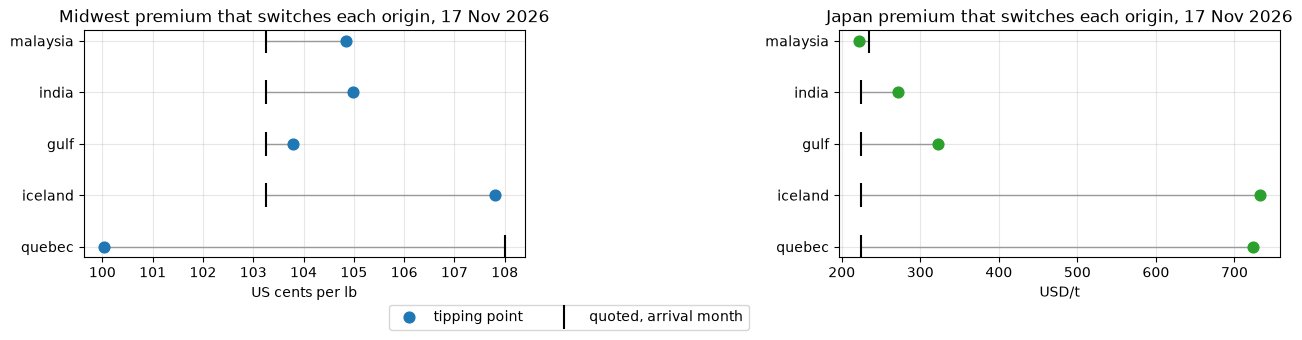

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
y = np.arange(len(ORIGINS))
for ax, market, unit in ((axes[0], "midwest", "US cents per lb"), (axes[1], "japan", "USD/t")):
    ax.scatter(ladder[f"{market}_tipping"], y, color=COLORS[market], s=60, label="tipping point", zorder=3)
    ax.scatter(ladder[f"{market}_quoted"], y, color="k", marker="|", s=300, label="quoted, arrival month", zorder=3)
    for i, o in enumerate(ORIGINS):
        ax.plot([ladder.loc[o, f"{market}_tipping"], ladder.loc[o, f"{market}_quoted"]], [i, i], color="0.6", lw=1)
    ax.set_yticks(y, ORIGINS); ax.set_xlabel(unit)
axes[0].legend(loc="upper center", bbox_to_anchor=(1.1, -0.18), ncols=2)
axes[0].set_title(f"Midwest premium that switches each origin, {last:%d %b %Y}")
axes[1].set_title(f"Japan premium that switches each origin, {last:%d %b %Y}")
plt.tight_layout();

In [11]:
ladder["midwest: quoted minus tipping"] = ladder["midwest_quoted"] - ladder["midwest_tipping"]
ladder["japan: quoted minus tipping"] = ladder["japan_quoted"] - ladder["japan_tipping"]
ladder

,best,midwest_quoted,midwest_tipping,japan_quoted,japan_tipping,midwest: quoted minus tipping,japan: quoted minus tipping
origin,,,,,,,
quebec,midwest,108.0,100.0,225.0,723.6,8.0,-498.6
iceland,rotterdam,103.2,107.8,225.0,732.5,-4.6,-507.5
gulf,rotterdam,103.2,103.8,225.0,322.4,-0.5,-97.4
india,rotterdam,103.2,105.0,225.0,271.9,-1.7,-46.9
malaysia,japan,103.2,104.9,234.6,222.0,-1.6,12.6


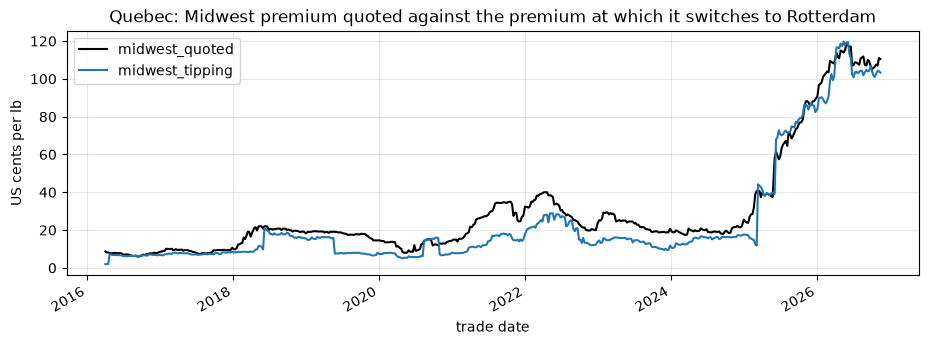

In [12]:
# the ladder over time: Quebec's tipping point against the Midwest premium it is quoted
history = pd.concat({d: netback.tipping(nb, d).loc["quebec"] for d in wide.index[::5]}).unstack()
ax = history[["midwest_quoted", "midwest_tipping"]].astype(float).plot(color=["k", COLORS["midwest"]], figsize=(11, 3.6))
ax.set_title("Quebec: Midwest premium quoted against the premium at which it switches to Rotterdam"); ax.set_ylabel("US cents per lb"); ax.set_xlabel("trade date");

- **Three origins sit on the edge of the Midwest.** The Gulf would leave Rotterdam for the Midwest at 103.8 c/lb against 103.2 quoted for December, India at 105.0 and Malaysia at 104.9. For metal east of Suez the Midwest is the marginal home.
- **Quebec is 8 cents clear, Iceland 4.6 short.** Quebec's November quote is 108.0 against a tipping point of 100.0; Iceland would need 107.8 to leave Rotterdam.
- **Japan is far from everyone but Malaysia.** It would take 272 USD/t to pull India and 322 to pull the Gulf, against 225 spot; Malaysia is 13 above its tipping point of 222.
- **Since the 50% duty Quebec's tipping point runs a few cents under the quote**, where it ran 10 to 20 cents under before 2025. The reading is that the Midwest premium has been set close to what it takes to keep Canadian metal in the US; it is a reading, not a test.

## 6. What the Midwest premium is made of

The Midwest premium is quoted duty-paid. Each day it is cut into the part that pays the section 232 duty on the metal and the premium that is left, the price of delivered metal in the US net of the tariff. Nobody publishes the second series.

/Users/malo/code/github/.venv/lib/python3.13/site-packages/pandas/plotting/_matplotlib/core.py:997: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  return ax.plot(*args, **kwds)


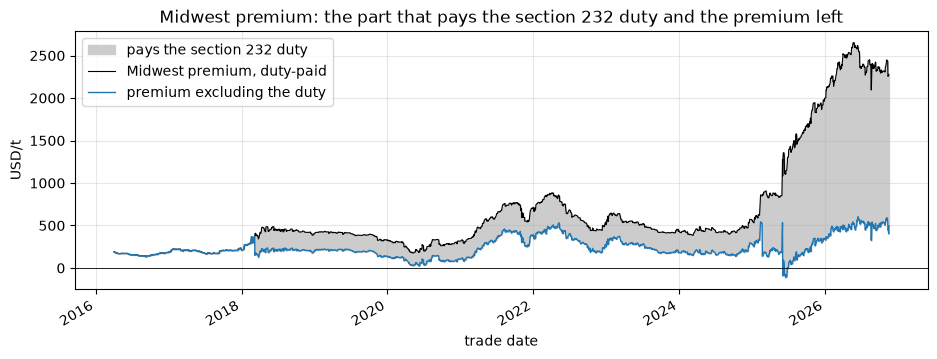

In [13]:
split = netback.midwest_split(data.dataset("iceland", "midwest", "direct"))
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.fill_between(split.index, split["excluding_duty"], split["premium"], color="0.8", label="pays the section 232 duty")
split["premium"].plot(ax=ax, color="k", lw=.8, label="Midwest premium, duty-paid")
split["excluding_duty"].plot(ax=ax, color=COLORS["midwest"], lw=1, label="premium excluding the duty")
ax.axhline(0, color="k", lw=.6); ax.legend(loc="upper left")
ax.set_title("Midwest premium: the part that pays the section 232 duty and the premium left"); ax.set_ylabel("USD/t"); ax.set_xlabel("trade date");

In [14]:
yearly = split.resample("YE").mean()
yearly.index = yearly.index.year
yearly.T

trade_date,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
premium,161.3,199.6,407.7,394.5,270.7,576.4,653.4,505.6,441.5,"1,275.3","2,372.7"
duty,0.0,0.0,187.0,198.7,179.5,277.8,305.1,250.5,260.0,"1,069.2","1,888.4"
excluding_duty,161.3,199.6,220.7,195.8,91.2,298.6,348.3,255.1,181.5,206.1,484.3


In [15]:
split.tail(3)

,premium,duty,excluding_duty
trade_date,,,
2026-11-13,"2,254.2","1,801.6",452.7
2026-11-16,"2,270.3","1,867.4",402.8
2026-11-17,"2,276.3","1,778.9",497.3


- **The duty share grows with each regime.** It was 46% of the premium in 2018 at 10%, 84% in 2025 and 80% in 2026. Before March 2018 the whole premium was premium.
- **When the duty-free supplier sets the price, the duty is not fully passed on.** The premium left fell to 91 USD/t in 2020, with Canada exempt; it turned negative in the spring of 2025, when the premium had not caught up with the 25% duty: tariff-paying metal lost money in the US for a few weeks.
- **At 484 USD/t on average in 2026 the premium left is the highest of the decade.** On top of the duty the US pays for metal it is short of.
- The split leaves the freight to the Midwest in the dutiable value, so the duty part is overstated by t/(1+t) of the delivery cost: about 30 USD/t at 50% and 100 USD/t of freight.

## 7. Historical replay

The same calculation on every trade date, each with the prices readable that evening. This is a replay of the economics, not a trading backtest: the premium futures are marks, often unchanged from one day to the next, and no position or P&L is simulated.

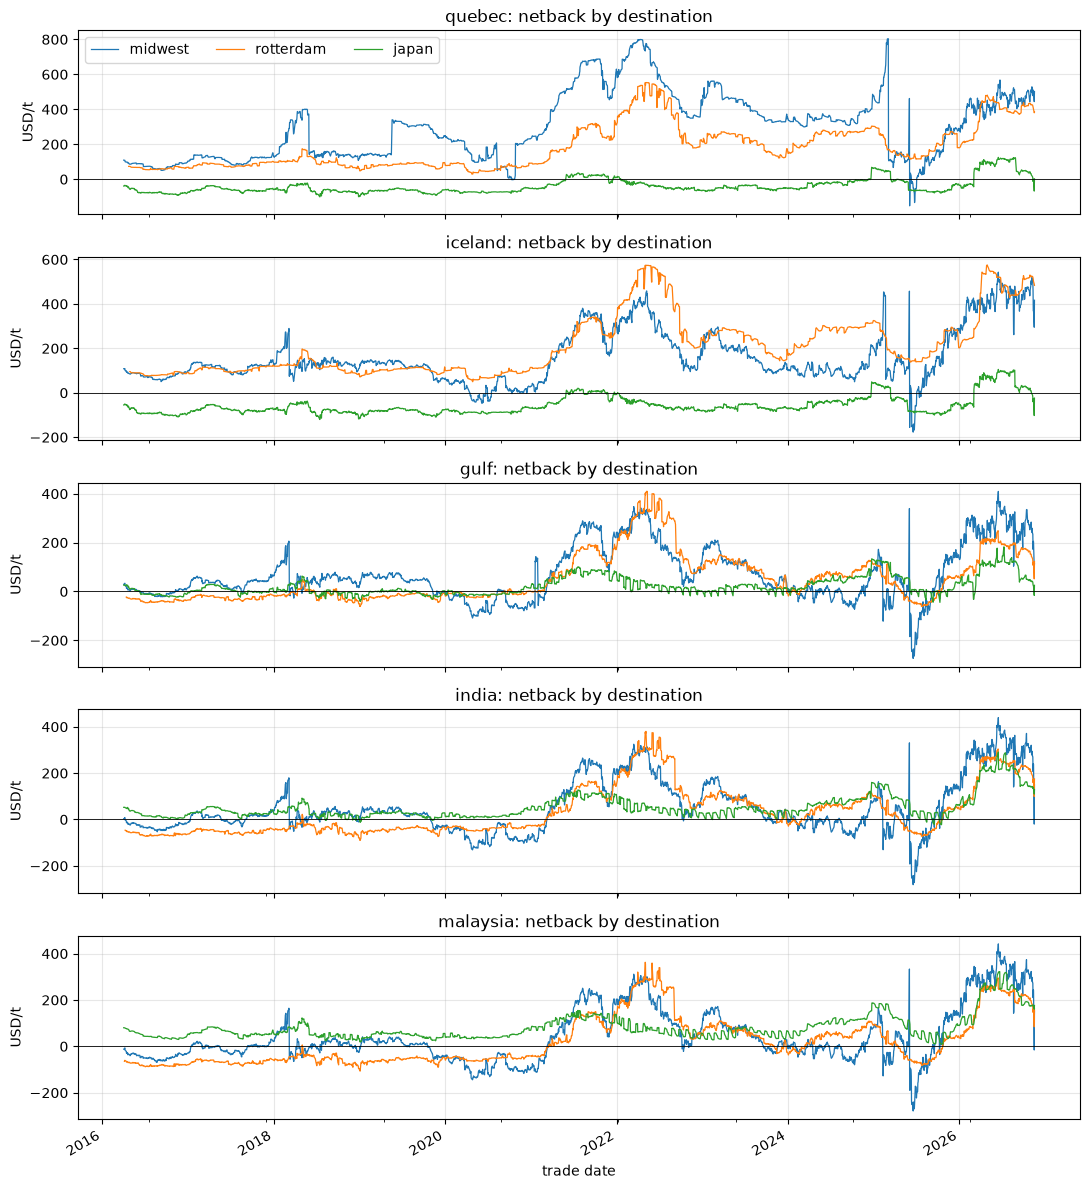

In [16]:
fig, axes = plt.subplots(len(ORIGINS), 1, figsize=(11, 12), sharex=True)
for ax, origin in zip(axes, ORIGINS):
    for destination in c.DESTINATIONS:
        wide[(origin, destination)].plot(ax=ax, color=COLORS[destination], lw=.9, label=destination)
    ax.axhline(0, color="k", lw=.6); ax.set_title(f"{origin}: netback by destination"); ax.set_ylabel("USD/t")
axes[0].legend(ncols=3); axes[-1].set_xlabel("trade date")
plt.tight_layout();

In [17]:
# the share of days each destination pays the most, under each origin's own section 232 rate
regime = {}
for origin in ORIGINS:
    t = data.dataset(origin, "midwest", "rail" if origin == "quebec" else "direct")["us_tariff"].reindex(best.index)
    regime[origin] = (100 * pd.crosstab(t.map("{:.0%}".format).rename("US duty"), best[origin], normalize="index")).reindex(columns=list(c.DESTINATIONS)).fillna(0)
pd.concat(regime).round(0)

midwest  rotterdam  japan
         US duty                           
quebec   0%          99.0        1.0    0.0
         10%         87.0       13.0    0.0
         25%         25.0       75.0    0.0
         50%         58.0       42.0    0.0
iceland  0%          59.0       41.0    0.0
         10%         30.0       70.0    0.0
         25%          6.0       94.0    0.0
         50%         27.0       73.0    0.0
gulf     0%          86.0        0.0   14.0
         10%         47.0       34.0   18.0
         25%          6.0        0.0   94.0
         50%         79.0        2.0   19.0
india    0%          13.0        0.0   87.0
         10%         36.0       17.0   47.0
         25%          1.0        0.0   99.0
         50%         75.0        4.0   22.0
malaysia 0%           7.0        0.0   93.0
         10%         16.0       11.0   74.0
         25%          1.0        0.0   99.0
         50%         71.0        1.0   29.0

In [18]:
# how often the best destination changes from one day to the next
(best != best.shift()).iloc[1:].sum().rename("switches")

quebec       32
iceland      91
gulf        147
india       142
malaysia     86
Name: switches, dtype: int64

In [19]:
# uncertainty: freight 30% lower and 30% higher; the share of days on which each origin's best destination is the same in both
low = netback.table(freight_scale=0.7).pivot_table(index="trade_date", columns=["origin", "destination"], values="netback")
high = netback.table(freight_scale=1.3).pivot_table(index="trade_date", columns=["origin", "destination"], values="netback")
holds = pd.Series({o: 100 * ((low[o].idxmax(axis=1) == best[o]) & (high[o].idxmax(axis=1) == best[o])).mean() for o in ORIGINS})
holds.rename("days the ranking holds with freight ±30%, %").to_frame().T

,quebec,iceland,gulf,india,malaysia
"days the ranking holds with freight ±30%, %",93.9,91.0,82.5,68.9,80.4


- **Before the tariffs the Gulf went west and Asia stayed in Asia.** Without a US duty the Midwest was the Gulf's best home on 86% of days and Japan that of India and Malaysia on 87% and 93%. The 25% interlude sent all three to Japan (94 to 99% of days); under 50% the Midwest takes 71 to 79% of days for all three.
- **Quebec and Iceland split the Atlantic.** Under 10% the Midwest won 87% of days for Quebec and Rotterdam 70% for Iceland. The 25% interlude sent both to Europe, Quebec on 75% of days and Iceland on 94%.
- **The ranking is solid where the gap is a tariff and fragile where it is freight.** Freight 30% lower and 30% higher leaves the best destination unchanged on 94% of days for Quebec and 91% for Iceland, 80 to 83% for the Gulf and Malaysia, 69% for India. The best destination changes 32 times in ten years for Quebec, 142 to 147 times for India and the Gulf.
- **The spikes in the Midwest lines are the duty's timing.** Some are real windows: in February and early March 2025 a Canadian tonne that landed before 12 March paid no duty but sold at a premium already pricing 25%. The one-day spike of early June 2025 is a convention: the 50% was announced on 30 May and signed on 3 June, and the netback only knows signed proclamations.

## 8. Routes, passages and chokepoint risk

Each route takes the passages searoute sends it through (notebook 01, section 6). PortWatch counts the container ships that cross each passage every day; a route's traffic is that of its most disrupted passage, against its 2019 average. The map, coloured by that traffic, is on the dashboard.

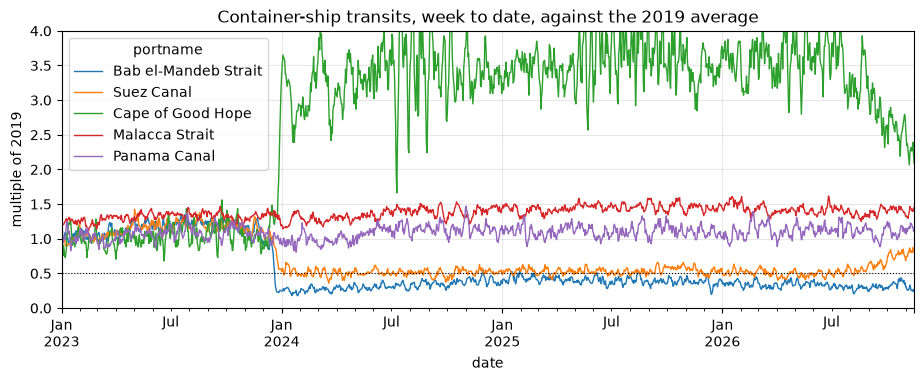

In [20]:
share = data.traffic()
weekly = share.pivot_table(index="date", columns="portname", values="share").loc["2023":]
ax = weekly[["Bab el-Mandeb Strait", "Suez Canal", "Cape of Good Hope", "Malacca Strait", "Panama Canal"]].plot(figsize=(11, 3.6), lw=1)
ax.axhline(c.CAPE_THRESHOLD, color="k", lw=.8, ls=":"); ax.set_ylim(0, 4)
ax.set_title("Container-ship transits, week to date, against the 2019 average"); ax.set_ylabel("multiple of 2019"); ax.set_xlabel("date");

In [21]:
# each route's passages and the traffic at its most disrupted one on the last trade date
traffic_now = pd.DataFrame([{"origin": x["origin"], "destination": x["destination"], "variant": x["variant"], "passages": x["passages"],
                             "traffic vs 2019": data.dataset(x["origin"], x["destination"], x["variant"]).loc[last, "traffic"]} for _, x in r.iterrows()])
traffic_now.set_index(["origin", "destination", "variant"])

passages  traffic vs 2019
origin   destination variant                                                     
quebec   midwest     rail                                                     NaN
         rotterdam   direct                                                   NaN
         japan       direct                               panama              1.1
iceland  midwest     direct                                                   NaN
         rotterdam   direct                                                   NaN
         japan       direct   babalmandab,malacca,suez,gibraltar              0.3
                     detour                               panama              1.1
gulf     midwest     direct           gibraltar,suez,babalmandab              0.3
                     detour                         south_africa              2.1
         rotterdam   direct           gibraltar,suez,babalmandab              0.3
                     detour                         south_africa              2.1
         japan       direct                              malacca              1.5
india    midwest     direct           gibraltar,suez,babalmandab              0.3
                     detour                         south_africa              2.1
         rotterdam   direct           gibraltar,suez,babalmandab              0.3
                     detour                         south_africa              2.1
         japan       direct                              malacca              1.5
malaysia midwest     direct   malacca,suez,babalmandab,gibraltar              0.3
                     detour                               panama              1.1
         rotterdam   direct   malacca,suez,babalmandab,gibraltar              0.3
                     detour                   sunda,south_africa              2.1
         japan       direct                                                   NaN

In [22]:
# what the rule chose, and what the detour cost against the direct voyage on the days it was chosen
pairs = r[r["variant"] == "detour"][["origin", "destination"]].drop_duplicates()
rows = []
for _, pair in pairs.iterrows():
    direct = netback.netback(pair["origin"], pair["destination"], "direct", data.dataset(pair["origin"], pair["destination"], "direct"))["netback"]
    detour = netback.netback(pair["origin"], pair["destination"], "detour", data.dataset(pair["origin"], pair["destination"], "detour"))["netback"]
    chosen = nb[(nb["origin"] == pair["origin"]) & (nb["destination"] == pair["destination"])].set_index("trade_date")["variant"]
    on = chosen[chosen == "detour"].index
    rows.append({"origin": pair["origin"], "destination": pair["destination"], "detour days": len(on), "first": on.min(),
                 "extra days at sea": float(r[(r["origin"] == pair["origin"]) & (r["destination"] == pair["destination"])]["sea_days"].diff().iloc[-1]),
                 "detour cost, mean USD/t": (direct - detour).reindex(on).mean(), "detour cost, last": (direct - detour).loc[last]})
pd.DataFrame(rows).set_index(["origin", "destination"])

detour days      first  extra days at sea  detour cost, mean USD/t  detour cost, last
origin   destination                                                                                       
iceland  japan                728 2023-12-27                0.6                      3.2                0.2
gulf     midwest              728 2023-12-27               10.2                     42.9              182.5
         rotterdam            728 2023-12-27               14.2                     75.6               91.8
india    midwest              728 2023-12-27                6.9                     29.8              167.9
         rotterdam            728 2023-12-27               11.0                     58.4               69.9
malaysia midwest              728 2023-12-27                3.1                     13.3              150.7
         rotterdam            728 2023-12-27                9.5                     50.8               60.2

- **The rule has picked the detour on every trade date since 27 December 2023.** Container transits at Bab el-Mandeb fell from 0.84 of 2019 to 0.23 in the week to 24 December 2023 and have stayed between 0.26 and 0.44 by quarter since; they were 0.33 in the latest weeks. Suez is back to 0.79, through traffic between the Mediterranean and the Red Sea ports rather than through the strait.
- **The detour adds 3 to 14 days at sea.** Its cost averages 76 USD/t for the Gulf to Rotterdam, 58 for India and 51 for Malaysia. On the last date it is 60 to 92 to Rotterdam and 150 to 183 to the Midwest, because the longer voyage arrives a month later and the January Midwest contract is 8 cents under December.
- **Hormuz is measured, not assumed.** The Gulf origin loads at Khor Fakkan, outside the strait, by construction. PortWatch has container transits at Hormuz at 3 to 8% of 2019 since April 2026: the closure the brief describes.

## 9. The voyage: what a day at anchor costs

A bulk cargo of 30,000 t from Khor Fakkan to Rotterdam under a voyage charter. The charter party allows a laytime; past it the charterer pays demurrage, before it the owner pays despatch. But a day at anchor costs the owner of the metal more than demurrage.

In [23]:
gulf = data.dataset("gulf", "rotterdam", "detour")
cost = voyage.day_cost(gulf)
cost.loc[[last]]

,demurrage,funding,curve,total
trade_date,,,,
2026-11-17,0.7,0.4,1.3,2.4


In [24]:
pd.DataFrame({(waiting, terms): voyage.laytime(waiting, terms) for waiting in (0, 2, 5, 10) for terms in ("SHINC", "SHEX")}).T.rename_axis(["waiting days", "terms"])

allowed_days  used_days  demurrage_usd  per_tonne
waiting days terms                                                   
0            SHINC          13.5       13.5            0.0        0.0
             SHEX           13.5       11.6      -19,285.7       -0.6
2            SHINC          13.5       15.0       30,000.0        1.0
             SHEX           13.5       12.9       -6,428.6       -0.2
5            SHINC          13.5       18.0       90,000.0        3.0
             SHEX           13.5       15.4       38,571.4        1.3
10           SHINC          13.5       23.0      190,000.0        6.3
             SHEX           13.5       19.7      124,285.7        4.1

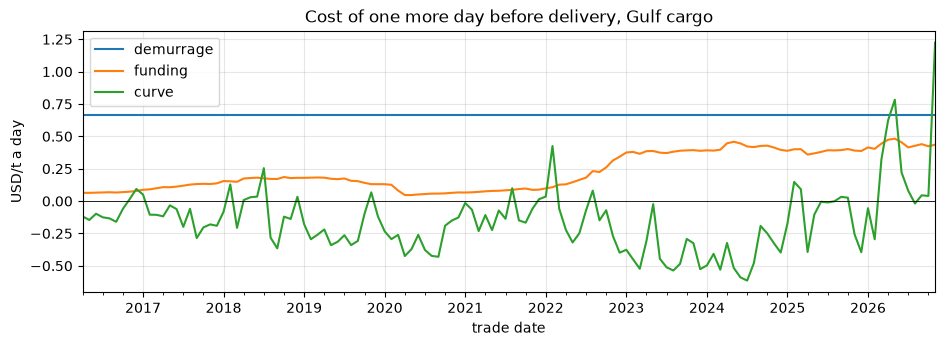

In [25]:
# a day at anchor through the sample: the curve is the part that moves
ax = cost[["demurrage", "funding", "curve"]].resample("ME").mean().plot(figsize=(11, 3.4))
ax.axhline(0, color="k", lw=.6); ax.set_title("Cost of one more day before delivery, Gulf cargo"); ax.set_ylabel("USD/t a day"); ax.set_xlabel("trade date");

In [26]:
# the days of waiting at its best destination that would make each origin switch to its second best, on the last trade date
day = voyage.day_cost(data.dataset("gulf", "rotterdam", "detour")).loc[last]
flip = pd.DataFrame({"best": findings["best"], "lead over second, USD/t": findings["lead over second"]})
flip["bulk: days at anchor"] = flip["lead over second, USD/t"] / day["total"]
flip["container: days, no ship demurrage"] = flip["lead over second, USD/t"] / (day["funding"] + day["curve"])
flip.loc[ORIGINS]

,best,"lead over second, USD/t",bulk: days at anchor,"container: days, no ship demurrage"
origin,,,,
quebec,midwest,117.2,48.2,66.5
iceland,rotterdam,67.0,27.6,38.0
gulf,rotterdam,8.0,3.3,4.6
india,rotterdam,25.6,10.5,14.5
malaysia,japan,12.6,5.2,7.1


**Container or bulk.** Most aluminium ingot moves in containers on liner services, not in chartered bulk carriers. Then there is no ship's demurrage for the cargo owner to pay: the liner sails on its schedule. The demurrage is that of the boxes at the terminal, charged by the carrier per box and per day once the free time agreed at booking has run out, and detention once the boxes leave the terminal and are not returned. The cost of a day that remains is the metal's own: funding and the LME curve, the two lines of the table that do not depend on the ship.

- **In this backwardation the curve costs more than the ship.** On 17 November one more day before delivery costs a tonne of Gulf metal 2.4 USD: 1.3 of LME curve, 0.7 of demurrage (20,000 USD a day over 30,000 t) and 0.4 of funding. A cargo at anchor loses more on the LME than it pays the shipowner.
- **Under the assumed terms the charter party allows 13.5 days.** Two days of waiting cost 30,000 USD of demurrage on SHINC terms; on SHEX terms the same voyage still earns despatch, because Sundays do not count.
- **Waiting that switches the decision.** The Gulf switches to its second best after 3 days at anchor at Rotterdam, Malaysia after 5 at Yokohama, India after 11; Quebec and Iceland would need 28 to 48 days. In containers, without a ship's demurrage, about a third longer.
- **The curve changes sign with the market.** Through the contango years a day before delivery cost only funding and demurrage less what the curve paid back; the backwardations of 2021-22 and of November 2026 are what make waiting expensive.

## 10. Sensitivities

One assumption moved at a time, everything else as in section 3. The table shows the change in each origin's lead of its best destination over its second best on the last trade date, in USD/t: a positive number makes the choice firmer, a negative one weakens it, and a change past the lead switches the destination.

In [27]:
def leads(**changes):
    """Each origin's netback at each destination on the last trade date, with some assumptions changed."""
    return netback.table(**changes).query("trade_date == @last").pivot(index="origin", columns="destination", values="netback").loc[ORIGINS]

base = leads()
cases = {"freight 30% lower": leads(freight_scale=0.7), "freight 30% higher": leads(freight_scale=1.3),
         "20 t a box instead of 22.5": leads(tonnes_per_box=20), "port days 5 instead of 10": leads(port_days=5),
         "funding spread 3.1% instead of 1.1%": leads(funding_spread=0.031), "land legs 50% dearer": leads(land_scale=1.5),
         "Rotterdam handling 40 instead of 20": leads(handling=40),
         "CBAM on emissions at the benchmark, no mark-up": leads(emissions=c.CBAM_BENCHMARK, cbam_markup=0.0),
         "US duty 25%: approved smelter projects": leads(us_tariff=0.25)}
mjp = netback.table().query("trade_date == @last").pivot(index="origin", columns="destination", values="netback").loc[ORIGINS]
mjp["japan"] = mjp["japan"] + 255 - pd.Series({o: data.dataset(o, "japan", "direct").loc[last, "premium_settle"] for o in ORIGINS})
cases["Japan at the Q4 benchmark, 255 USD/t"] = mjp
best_now = base.idxmax(axis=1)
lead = lambda nb_: pd.Series({o: nb_.loc[o, best_now[o]] - nb_.loc[o].drop(best_now[o]).max() for o in ORIGINS})
sensitivity = pd.DataFrame({name: lead(case) - lead(base) for name, case in cases.items()}).T
switched = pd.DataFrame({name: case.idxmax(axis=1) != best_now for name, case in cases.items()}).T
sensitivity.loc["base case: best destination"] = best_now
sensitivity.loc["base case: lead over second, USD/t"] = lead(base).round(1)
sensitivity

,quebec,iceland,gulf,india,malaysia
freight 30% lower,-12.1,-2.8,14.0,15.0,-42.7
freight 30% higher,12.1,2.8,-14.0,-15.0,35.4
20 t a box instead of 22.5,0.0,0.0,-2.8,0.0,0.0
port days 5 instead of 10,-0.7,0.7,0.7,0.7,0.0
funding spread 3.1% instead of 1.1%,1.2,0.9,-1.0,-1.1,4.9
land legs 50% dearer,-26.7,13.3,13.3,13.3,0.0
Rotterdam handling 40 instead of 20,20.0,-20.0,-20.0,-20.0,10.9
"CBAM on emissions at the benchmark, no mark-up",-66.6,-3.2,0.0,0.0,0.0
US duty 25%: approved smelter projects,712.3,-695.4,-635.0,-642.0,-631.7
"Japan at the Q4 benchmark, 255 USD/t",0.0,0.0,0.0,-8.7,20.4


In [28]:
# the cases that switch an origin's destination on the last trade date
switched[switched.any(axis=1)]

origin,quebec,iceland,gulf,india,malaysia
freight 30% lower,False,False,False,False,True
freight 30% higher,False,False,True,False,False
Rotterdam handling 40 instead of 20,False,False,True,False,False
US duty 25%: approved smelter projects,False,True,True,True,True


- **Freight is the assumption that matters east of Suez.** Freight 30% higher or lower moves the Gulf's and India's lead by 14 to 15 USD/t, more than the Gulf's lead of 8: dearer freight sends the Gulf to the Midwest, cheaper freight takes Malaysia away from Japan.
- **Everything else moves a lead by 27 USD/t or less.** Land legs 50% dearer cost Quebec 27 of its 117; a Rotterdam handling charge of 40 instead of 20 costs every Rotterdam origin 20 and switches the Gulf. The box load, port days and funding spread move a lead by under 5.
- **CBAM on real emissions would change Quebec's arithmetic, not its answer.** At emissions equal to the CBAM benchmark, which an efficient hydro-powered smelter can approach, Rotterdam gains 67 USD/t for Quebec: still 50 short of the Midwest.
- **Japan at the Q4 benchmark of 255 instead of the spot 225** firms Malaysia's choice of Japan by 20 USD/t and changes nobody else's.
- **The half rate of the July 2026 onshoring programme is a rent, not a sensitivity.** Importing at 25% instead of 50% is worth 630 to 710 USD/t on today's numbers and would send every origin to the Midwest, but only for the tonnes of an approved plan.

## 11. Limitations

- **Marks, not trades.** The four premium futures settle on price agencies' assessments and are often unchanged from one day to the next: 70 to 80% of days for the duty-unpaid and Japan contracts. The duty-paid contract is within 2 to 8 USD/t of the five press assessments checked (notebook 01), but five is few: the agency series are paid and the hand-typed check is sparse.
- **One contract per arrival month.** The premium is the futures average for the month the metal lands, so the netback jumps when the arrival date crosses a month end, and a longer route sells into a later contract.
- **Freight calibrated, not quoted.** One Drewry lane, per tonne and nautical mile, held flat over ten years: the 2021 container spike and the Red Sea surcharges of 2024 are not in the replay. Section 10 shows it is the assumption that matters.
- **The US duty on an approximate value.** Customs value is the price paid for the metal, here approximated by the FOB netback; the duty is the one in signed proclamations, not in announcements.
- **Annual contracts are invisible.** Most primary aluminium moves under annual contracts priced on these premiums; the netback is the decision for the next spot tonne, not for the book.
- **CBAM on default values.** A producer reporting verified emissions pays far less (section 10). Before the Commission's first certificate price, on 7 April 2026, a duty-paid sale paying CBAM is not taken.
- **Coordinates and speed.** Distances are searoute's network between port coordinates; one speed for every ship, ten port days for every voyage, a fixed land leg.
- **Thin surcharges.** Two carrier notices with their dates; none on file before 2026.
- **The route rule is a threshold on AIS counts.** PortWatch revises its history when it adds vessels, and warns of GPS jamming in the Gulf; one download is used.
- **Not a margin.** The cost of making the metal cancels between destinations and is left out: the netback says where a tonne should go, not whether it should be produced.

## 12. Conclusion

On settlement marks, between April 2016 and November 2026, the best home for a tonne of primary aluminium has been set by the US tariff first and by freight second. Without a duty Indian and Malaysian metal went to Japan; at 50% the Midwest premium more than refunds the duty and pulls the Gulf, India and Malaysia, and today they sit within two cents a pound of switching.

For a desk the useful object is the ladder of section 5: one tipping premium per origin, against the premium quoted for its arrival month. The outright premium alone misreads the arbitrage whenever the duty, the freight or the arrival month changes.

Notebook 03 checks the answer against the tonnes that moved.